# **Data Preprocessing: Diabetes Health Indicators (BRFSS 2015)**

Notebook ini menjalankan seluruh tahap preprocessing sebelum data masuk ke model MLP. Setiap keputusan diambil berdasarkan temuan di `01_eda.ipynb`, lalu dikunci di `src/preprocessing.py` supaya notebook model, evaluasi, dan aplikasi memakai pipeline yang sama persis.

**Penanggung jawab:** Felix Malvin (231111970)

## **1. Import Library dan Konfigurasi**

In [1]:
import sys
import hashlib
import platform
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import skew

from src import config
from src import preprocessing as prep

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Python       :", platform.python_version())
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("Seed         :", config.SEED)

Python       : 3.12.10
pandas       : 3.1.0
scikit-learn : 1.9.1
Seed         : 42


## **2. Memuat Data dan Memeriksa Nilai yang Rusak**

Data dibaca lewat `load_raw_data()`, yang sekaligus mengubah semua kolom dari `float64` ke integer. Setelah itu setiap kolom dicek apakah nilainya masih berada di dalam kode yang sah menurut codebook BRFSS. Nilai di luar kode, misalnya `Age = 14` atau `HighBP = 2`, dianggap sebagai data rusak. Pemeriksaan missing value juga dilakukan di sini.

In [2]:
df_raw = prep.load_raw_data()
print(f"Ukuran data mentah : {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
print(f"Total missing value: {int(df_raw.isna().sum().sum())}")

valid_range = {col: (0, 1) for col in config.BINARY_COLS + [config.TARGET_COL]}
valid_range.update({"GenHlth": (1, 5), "Age": (1, 13), "Education": (1, 6), "Income": (1, 8),
                    "MentHlth": (0, 30), "PhysHlth": (0, 30)})

cek = []
for col, (lo, hi) in valid_range.items():
    di_luar = ((df_raw[col] < lo) | (df_raw[col] > hi)).sum()
    cek.append({"kolom": col, "rentang_sah": f"{lo}-{hi}", "min": df_raw[col].min(),
                "max": df_raw[col].max(), "nilai_di_luar_rentang": int(di_luar)})
cek = pd.DataFrame(cek)
print(f"Total nilai di luar kode yang sah: {cek['nilai_di_luar_rentang'].sum()}")
cek

Ukuran data mentah : 253,680 baris x 22 kolom
Total missing value: 0
Total nilai di luar kode yang sah: 0


,kolom,rentang_sah,min,max,nilai_di_luar_rentang
0,HighBP,0-1,0,1,0
1,HighChol,0-1,0,1,0
2,CholCheck,0-1,0,1,0
3,Smoker,0-1,0,1,0
4,Stroke,0-1,0,1,0
5,HeartDiseaseorAttack,0-1,0,1,0
6,PhysActivity,0-1,0,1,0
7,Fruits,0-1,0,1,0
8,Veggies,0-1,0,1,0
9,HvyAlcoholConsump,0-1,0,1,0


**Interpretasi:** Tidak ada missing value dan tidak ada satu pun nilai yang keluar dari kode sah codebook BRFSS. Semua fitur biner hanya berisi 0 dan 1, kategori umur tetap di 1 sampai 13, dan jumlah hari sakit tetap di 0 sampai 30. Jadi dataset ini sudah melalui pembersihan dasar dari pembuatnya di Kaggle, sehingga tahap imputasi tidak diperlukan. Satu-satunya kolom yang tidak bisa dicek dengan cara ini adalah `BMI`, karena BMI tidak punya kode tetap dan harus dinilai dari kewajaran nilainya (Bagian 4).

## **3. Menghapus Data Duplikat**

Baris yang identik di seluruh 22 kolom dihapus dan hanya disisakan satu salinan. Alasan utamanya adalah mencegah baris yang sama persis muncul di data train sekaligus test. Komposisi kelas sebelum dan sesudah penghapusan juga dibandingkan, karena dari EDA diketahui duplikat didominasi kelas negatif.

In [3]:
df_dedup = df_raw.drop_duplicates().reset_index(drop=True)

def komposisi(df):
    vc = df[config.TARGET_COL].value_counts().sort_index()
    return vc.values.tolist() + [round(vc[1] / vc.sum() * 100, 2)]

tabel_dup = pd.DataFrame(
    [komposisi(df_raw), komposisi(df_dedup)],
    index=["Sebelum", "Sesudah"],
    columns=["kelas_0", "kelas_1", "persen_kelas_1"],
)
tabel_dup["total"] = tabel_dup["kelas_0"] + tabel_dup["kelas_1"]
display(tabel_dup)
print(f"Baris dihapus: {len(df_raw) - len(df_dedup):,}")

,kelas_0,kelas_1,persen_kelas_1,total
Sebelum,218334,35346,13.93,253680
Sesudah,194377,35097,15.29,229474


Baris dihapus: 24,206


**Interpretasi:** Sebanyak 24.206 baris duplikat dihapus sehingga data tersisa 229.474 baris. Hampir semua baris yang terhapus berasal dari kelas 0 (jumlahnya turun dari 218.334 ke 194.377), sedangkan kelas 1 hanya berkurang 249 baris. Akibatnya proporsi kelas 1 naik dari 13,93% menjadi 15,29%.

Keputusan ini punya konsekuensi yang perlu dicatat. Setelah duplikat dihapus, setiap pola jawaban survei hanya dihitung sekali, sehingga data tidak lagi sama persis dengan proporsi populasi survei aslinya. Probabilitas keluaran model juga akan sedikit lebih tinggi dibanding kalau model dilatih dengan data mentah. Kami tetap memilih menghapus duplikat karena risiko sebaliknya lebih berbahaya untuk evaluasi, yaitu salinan baris yang sama tersebar di train dan test sehingga skor test terlihat lebih bagus dari kemampuan model yang sebenarnya.

## **4. Penanganan Outlier BMI**

EDA menunjukkan persentase diabetes turun drastis pada BMI 70 ke atas. Kalau keputusan menghapus baris hanya didasarkan pada pola label, ada risiko data "dirapikan" supaya skor model naik. Karena itu, bukti di bagian ini sengaja memakai **fitur lain yang bukan label**, yaitu kesulitan berjalan (`DiffWalk`), tekanan darah tinggi (`HighBP`), penilaian kesehatan umum (`GenHlth`), dan aktivitas fisik (`PhysActivity`). Orang dengan BMI sangat ekstrem secara medis hampir pasti menunjukkan kondisi yang lebih berat pada fitur-fitur ini.

In [4]:
bins = [0, 25, 30, 40, 50, 55, 60, 65, 70, 75, 80, 90, 100]
labels = ["<25", "25-29", "30-39", "40-49", "50-54", "55-59", "60-64", "65-69",
          "70-74", "75-79", "80-89", "90+"]
grp = pd.cut(df_dedup["BMI"], bins=bins, labels=labels, right=False)

bukti = df_dedup.groupby(grp, observed=True).agg(
    jumlah=("BMI", "size"),
    DiffWalk=("DiffWalk", "mean"),
    HighBP=("HighBP", "mean"),
    PhysActivity=("PhysActivity", "mean"),
    GenHlth_rata2=("GenHlth", "mean"),
)
for col in ["DiffWalk", "HighBP", "PhysActivity"]:
    bukti[col] = (bukti[col] * 100).round(1)
bukti["GenHlth_rata2"] = bukti["GenHlth_rata2"].round(2)
bukti.columns = ["jumlah", "% DiffWalk", "% HighBP", "% PhysActivity", "GenHlth rata-rata"]
bukti

,jumlah,% DiffWalk,% HighBP,% PhysActivity,GenHlth rata-rata
BMI,,,,,
<25,61894,12.7,31.0,79.1,2.37
25-29,82723,15.0,44.1,75.7,2.51
30-39,71141,23.4,55.9,68.7,2.80
40-49,11169,39.8,64.8,57.8,3.20
50-54,1190,55.9,68.2,51.0,3.44
55-59,489,62.6,72.6,41.3,3.66
60-64,199,70.9,72.4,44.7,3.79
65-69,70,74.3,71.4,48.6,3.89
70-74,141,28.4,47.5,69.5,2.65


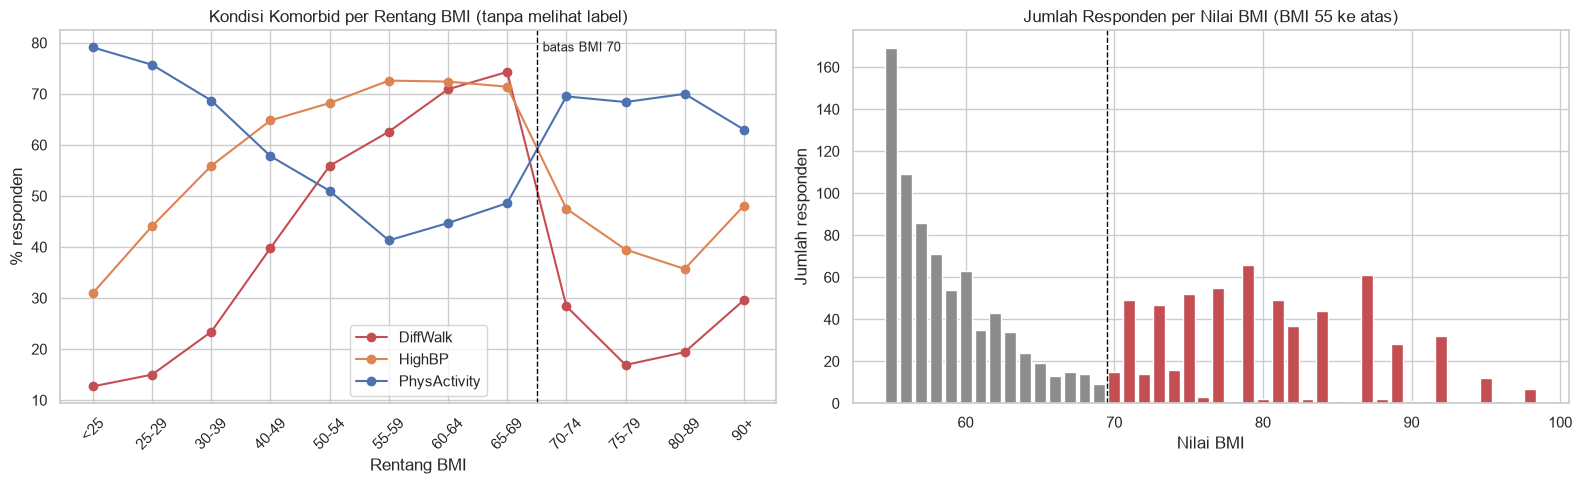

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
for col, warna in [("% DiffWalk", "#C44E52"), ("% HighBP", "#DD8452"), ("% PhysActivity", "#4C72B0")]:
    ax.plot(bukti.index.astype(str), bukti[col], marker="o", label=col.replace("% ", ""), color=warna)
ax.axvline(7.5, ls="--", color="black", lw=1)
ax.text(7.6, ax.get_ylim()[1] * 0.95, "batas BMI 70", fontsize=9)
ax.set_title("Kondisi Komorbid per Rentang BMI (tanpa melihat label)")
ax.set_xlabel("Rentang BMI")
ax.set_ylabel("% responden")
ax.tick_params(axis="x", rotation=45)
ax.legend()

ax = axes[1]
vc = df_dedup.loc[df_dedup["BMI"] >= 55, "BMI"].value_counts().sort_index()
warna_bar = ["#8C8C8C" if v < 70 else "#C44E52" for v in vc.index]
ax.bar(vc.index, vc.values, color=warna_bar)
ax.axvline(69.5, ls="--", color="black", lw=1)
ax.set_title("Jumlah Responden per Nilai BMI (BMI 55 ke atas)")
ax.set_xlabel("Nilai BMI")
ax.set_ylabel("Jumlah responden")

fig.tight_layout()
save_fig(fig, "prep_01_bukti_outlier_bmi")
plt.show()

In [6]:
# Pola nilai ganjil-genap di atas BMI 70
atas = df_dedup.loc[df_dedup["BMI"].between(70, 89), "BMI"]
bawah = df_dedup.loc[df_dedup["BMI"].between(50, 69), "BMI"]
for nama, s in [("BMI 50-69", bawah), ("BMI 70-89", atas)]:
    ganjil = (s % 2 == 1).mean()
    print(f"{nama}: {len(s):>5} baris, proporsi nilai ganjil = {ganjil:.1%}")

print(f"\nBMI di bawah 15 (batas bawah ekstrem): {(df_dedup['BMI'] < 15).sum()} baris")

BMI 50-69:  1948 baris, proporsi nilai ganjil = 46.8%
BMI 70-89:   545 baris, proporsi nilai ganjil = 75.2%

BMI di bawah 15 (batas bawah ekstrem): 68 baris


In [7]:
n_sebelum = len(df_dedup)
df_clean = df_dedup[df_dedup["BMI"] <= config.BMI_MAX_VALID].reset_index(drop=True)
print(f"Batas BMI yang dipakai       : <= {config.BMI_MAX_VALID}")
print(f"Baris dihapus karena BMI >= 70: {n_sebelum - len(df_clean):,} "
      f"({(n_sebelum - len(df_clean)) / n_sebelum:.2%})")
print(f"Ukuran data setelah cleaning : {len(df_clean):,} baris")
print(f"Persentase kelas 1           : {df_clean[config.TARGET_COL].mean():.2%}")

Batas BMI yang dipakai       : <= 69
Baris dihapus karena BMI >= 70: 599 (0.26%)
Ukuran data setelah cleaning : 228,875 baris
Persentase kelas 1           : 15.30%


**Interpretasi:** Bukti dari fitur nonlabel menunjukkan perubahan yang sangat tajam tepat di BMI 70.

Dari BMI di bawah 25 sampai BMI 65 hingga 69, kondisi responden memburuk secara konsisten. Persentase yang sulit berjalan naik dari 12,7% menjadi 74,3%, persentase yang aktif berolahraga turun dari 79,1% menjadi 48,6%, dan rata-rata `GenHlth` naik dari 2,37 menjadi 3,89. Pola ini masuk akal secara medis karena obesitas berat memang membatasi gerak tubuh.

Begitu masuk BMI 70 sampai 74, semuanya mendadak kembali seperti populasi umum. Hanya 28,4% yang sulit berjalan dan 69,5% aktif berolahraga, mirip dengan kelompok BMI 30 sampai 39. Orang dengan BMI di atas 70 hampir mustahil punya profil kesehatan seperti itu.

Grafik kanan memperkuat dugaan ini. Jumlah responden turun perlahan sampai BMI 69, lalu di atas 70 muncul lonjakan hanya pada angka ganjil. Proporsi nilai ganjil di rentang BMI 70 sampai 89 mencapai 75,2%, padahal di rentang 50 sampai 69 hanya 46,8% atau hampir seimbang seperti seharusnya. Pola seperti ini lebih cocok dijelaskan sebagai artefak perhitungan dari tinggi atau berat badan yang salah diisi, bukan sebaran orang sungguhan.

Karena itu 599 baris dengan BMI 70 ke atas dihapus (0,26% data). Opsi clipping tidak dipakai karena akan memindahkan responden yang profilnya mirip orang ber-BMI normal ke nilai BMI 69, yaitu zona dengan kondisi kesehatan paling buruk. Penghapusan ini juga berlaku untuk data test, karena batas yang sama nantinya dipakai sebagai rentang input sah di aplikasi. Di sisi lain, 68 baris dengan BMI di bawah 15 tetap dipertahankan karena jumlahnya kecil dan tidak menunjukkan pola janggal.

Data bersih akhirnya berjumlah 228.875 baris dengan proporsi kelas 1 sebesar 15,30%.

## **5. Pemeriksaan Label yang Ambigu**

Setelah duplikat dihapus, masih ada profil fitur yang muncul dua kali dengan label berbeda (satu berlabel 0 dan satu berlabel 1). Baris seperti ini tidak bisa disebut "label salah", karena dua responden berbeda memang bisa punya jawaban survei yang sama tetapi status diabetes berbeda. Bagian ini menghitung jumlahnya sebagai catatan batas kemampuan model.

In [8]:
fitur = config.FEATURE_COLS
n_label = df_clean.groupby(fitur)[config.TARGET_COL].transform("nunique")
ambigu = df_clean[n_label > 1]
print(f"Baris dengan profil fitur ambigu : {len(ambigu):,} ({len(ambigu) / len(df_clean):.2%} dari data bersih)")
print(f"Jumlah profil fitur ambigu       : {ambigu.groupby(fitur).ngroups:,}")

Baris dengan profil fitur ambigu : 3,132 (1.37% dari data bersih)
Jumlah profil fitur ambigu       : 1,566


**Interpretasi:** Ada 1.566 profil fitur yang masing-masing muncul tepat dua kali dengan label berbeda, totalnya 3.132 baris atau 1,37% dari data bersih. Untuk setiap pasangan ini, model hanya bisa benar pada salah satunya karena inputnya sama persis. Baris-baris ini tidak dihapus karena memang mencerminkan keterbatasan data survei, yaitu 21 fitur yang sebagian besar berupa jawaban ya atau tidak belum cukup untuk membedakan semua orang. Temuan ini bisa dipakai di laporan bagian 1 sebagai salah satu alasan kenapa masalah ini sulit.

## **6. Verifikasi Pipeline Cleaning di `src/preprocessing.py`**

Langkah 2 sampai 4 di atas dikerjakan manual supaya prosesnya terlihat. Notebook lain tidak akan mengulang langkah manual ini, tetapi memanggil `prep.get_splits()`. Karena itu hasil fungsi tersebut harus dicek sama persis dengan hasil manual.

In [9]:
df_fungsi, ringkasan = prep.clean_data(prep.load_raw_data())
print(pd.Series(ringkasan).to_string())
print("\nHasil fungsi identik dengan langkah manual:", df_fungsi.equals(df_clean))

rows_raw                253680
duplicates_removed       24206
bmi_outliers_removed       599
rows_clean              228875

Hasil fungsi identik dengan langkah manual: True


## **7. Pembagian Data Train, Validation, dan Test**

Data dibagi 70% train, 15% validation, dan 15% test dengan `train_test_split` berstratifikasi pada label, sehingga proporsi kelas 1 di ketiga bagian tetap sama. Seed dikunci di `config.SEED = 42`, jadi siapa pun yang menjalankan `get_splits()` akan mendapat pembagian yang identik.

Peran tiap bagian:
- **Train:** melatih bobot model dan fit scaler.
- **Validation:** memilih hyperparameter, EarlyStopping, dan menentukan threshold (fitur unik 1).
- **Test:** hanya dipakai **satu kali** di evaluasi akhir.

,jumlah,proporsi_data,kelas_0,kelas_1,persen_kelas_1
train,160211,70.0,135700,24511,15.3
val,34332,15.0,29080,5252,15.3
test,34332,15.0,29079,5253,15.3


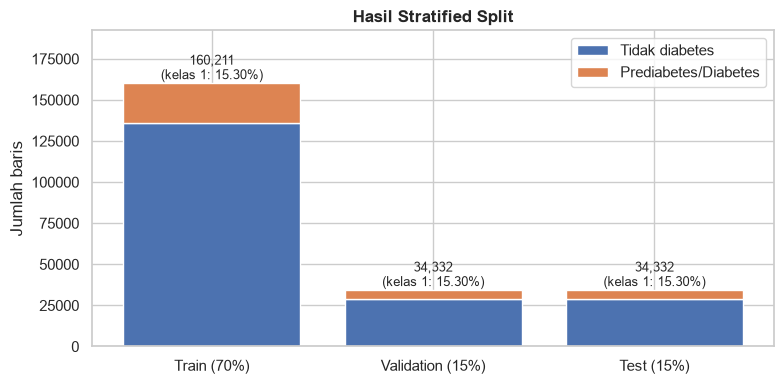

In [10]:
splits = prep.split_data(df_clean)

tabel_split = pd.DataFrame({
    part: {
        "jumlah": len(splits[f"y_{part}"]),
        "proporsi_data": len(splits[f"y_{part}"]) / len(df_clean) * 100,
        "kelas_0": int((splits[f"y_{part}"] == 0).sum()),
        "kelas_1": int((splits[f"y_{part}"] == 1).sum()),
        "persen_kelas_1": splits[f"y_{part}"].mean() * 100,
    }
    for part in ["train", "val", "test"]
}).T
tabel_split[["jumlah", "kelas_0", "kelas_1"]] = tabel_split[["jumlah", "kelas_0", "kelas_1"]].astype(int)
display(tabel_split.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3)
ax.bar(x, tabel_split["kelas_0"], label="Tidak diabetes", color="#4C72B0")
ax.bar(x, tabel_split["kelas_1"], bottom=tabel_split["kelas_0"], label="Prediabetes/Diabetes", color="#DD8452")
for i, (tot, pct) in enumerate(zip(tabel_split["jumlah"], tabel_split["persen_kelas_1"])):
    ax.text(i, tot, f"{tot:,}\n(kelas 1: {pct:.2f}%)", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, ["Train (70%)", "Validation (15%)", "Test (15%)"])
ax.set_ylabel("Jumlah baris")
ax.set_ylim(0, tabel_split["jumlah"].max() * 1.2)
ax.set_title("Hasil Stratified Split", fontweight="bold")
ax.legend()
fig.tight_layout()
save_fig(fig, "prep_02_distribusi_split")
plt.show()

**Interpretasi:** Hasil pembagian data adalah 160.211 baris train, 34.332 baris validation, dan 34.332 baris test, tepat sesuai proporsi 70/15/15. Stratifikasi bekerja dengan baik karena persentase kelas 1 di ketiga bagian sama-sama 15,30%. Dengan begitu, hasil evaluasi di validation dan test bisa dibandingkan langsung tanpa terganggu perbedaan komposisi kelas.

### **7.1 Pemeriksaan Kebocoran Data**

Ada tiga hal yang dicek untuk memastikan tidak ada kebocoran data antar bagian:
1. Tidak ada index baris yang sama di dua bagian berbeda.
2. Tidak ada baris identik (fitur dan label) yang muncul di train sekaligus test.
3. Jumlah vektor fitur yang sama di train dan test, yang hanya mungkin berasal dari profil ambigu di Bagian 5.

Selain itu, fingerprint index data test disimpan. Notebook evaluasi akhir akan mencocokkan fingerprint ini untuk membuktikan data test yang dipakai sama persis.

In [11]:
idx = {p: set(splits[f"X_{p}"].index) for p in ["train", "val", "test"]}
print("Index train-val beririsan :", len(idx["train"] & idx["val"]))
print("Index train-test beririsan:", len(idx["train"] & idx["test"]))
print("Index val-test beririsan  :", len(idx["val"] & idx["test"]))

def gabung(p):
    return splits[f"X_{p}"].assign(**{config.TARGET_COL: splits[f"y_{p}"]})

baris_sama = gabung("train").merge(gabung("test"), on=fitur + [config.TARGET_COL], how="inner")
print("\nBaris identik (fitur + label) di train dan test:", len(baris_sama))

fitur_sama = splits["X_train"].drop_duplicates().merge(splits["X_test"], on=fitur, how="inner")
print("Vektor fitur sama di train dan test (label berbeda):", len(fitur_sama))

test_fp = prep.split_fingerprint(splits["X_test"].index)
print("\nFingerprint data test:", test_fp)

Index train-val beririsan : 0
Index train-test beririsan: 0
Index val-test beririsan  : 0

Baris identik (fitur + label) di train dan test: 0
Vektor fitur sama di train dan test (label berbeda): 342

Fingerprint data test: 01b58633cb6f22b5


**Interpretasi:** Tidak ada index baris yang dipakai di dua bagian sekaligus, dan tidak ada baris identik (fitur dan label) yang muncul di train maupun test. Penghapusan duplikat di Bagian 3 berhasil menutup jalur kebocoran yang paling umum.

Masih ada 342 vektor fitur yang muncul di train dan test, tetapi semuanya dengan label berbeda. Ini adalah profil ambigu dari Bagian 5 yang kebetulan terpecah ke dua bagian. Kasus ini tidak termasuk kebocoran, karena yang dilihat model di train justru label kebalikannya, sehingga baris tersebut malah menurunkan skor test, bukan menaikkannya.

Fingerprint data test (`01b58633cb6f22b5`) disimpan di `preprocessing_config.json` dan wajib dicocokkan di notebook evaluasi akhir.